In [1]:
from pathlib import Path 
import os
import dotenv
dotenv.load_dotenv()
os.chdir(Path(os.getenv("PYTHONPATH")).expanduser())

# Why `dt=0.001`, `t=1,000,000`, and `stride=50` for ESN on Lorenz‑63

This notebook motivates and **visualizes** the sampling/stride choices for training an Echo State Network (ESN) on the Lorenz‑63 dynamical system.

**Key ideas:**  
- `dt = 0.001` ⇒ sampling rate `fs = 1/dt = 1000 Hz`, comfortably above the effective bandwidth of Lorenz‑63 trajectories (so we avoid aliasing and get smooth derivatives).  
- `t = 1,000,000` ⇒ (conceptually) very long trajectory to cover the strange attractor thoroughly and de-correlate training samples across many lobe transitions.  
- `stride = 50` ⇒ downsample from `1000 Hz` to `20 Hz`, which preserves most low‑frequency energy while shrinking the data size and improving ESN training/runtime stability.

Below we **visualize** the frequency- and time-domain effects of this stride using the functions defined in `series_statistics.py`. For runtime reasons, we demonstrate on a shorter simulated segment; the same code paths apply to the long run.


## 1. Generate a Lorenz‑63 segment (demo)

We integrate the classical Lorenz‑63 ODE with parameters `(σ=10, ρ=28, β=8/3)` using RK4.  
We set `dt=0.001` (=> `fs=1000 Hz`). For demonstration we simulate `t_demo = 200` seconds  
(**200k** points) which is sufficient to exhibit lobe transitions and yield stable spectral estimates.  


In [2]:
import seaborn as sns
import numpy as np

# Lorenz-63 parameters
sigma, rho, beta = 10.0, 28.0, 8.0/3.0

def lorenz63(state):
    x, y, z = state
    dx = sigma * (y - x)
    dy = x * (rho - z) - y
    dz = x * y - beta * z
    return np.array([dx, dy, dz], dtype=float)

def rk4_step(f, y, dt):
    k1 = f(y)
    k2 = f(y + 0.5*dt*k1)
    k3 = f(y + 0.5*dt*k2)
    k4 = f(y + dt*k3)
    return y + (dt/6.0)*(k1 + 2*k2 + 2*k3 + k4)

# Simulation parameters
dt = 0.001
fs = 1.0 / dt
t_demo = 10_000  # seconds (demo only)
n_steps = int(t_demo / dt)

# Burn-in
y = np.array([1.0, 1.0, 1.0], dtype=float)
for _ in range(5000):
    y = rk4_step(lorenz63, y, dt)

# Generate trajectory
xs = np.empty(n_steps); ys = np.empty(n_steps); zs = np.empty(n_steps)
state = y.copy()
for i in range(n_steps):
    xs[i], ys[i], zs[i] = state
    state = rk4_step(lorenz63, state, dt)

t = np.arange(n_steps) * dt
len(xs), fs

(10000000, 1000.0)

## 2. Import `series_statistics.py` helpers

We use `analyze_resampling_axes` to compute:
- **NRMSE** and **correlation** in time domain (original vs down/up-sampled)
- **PSD energy below** a chosen cutoff `f_cut`
- **Jensen–Shannon divergence** between PSDs

and to produce diagnostic plots.


In [3]:
import importlib.util, sys, inspect, pandas as pd, matplotlib.pyplot as plt
import src.series_statistics as ss
print("Available functions:", [k for k,v in ss.__dict__.items() if callable(v)])

Available functions: ['welch', 'resample_poly', 'jensenshannon', 'psd_energy_below', 'jsd_psd', 'resample_to_original', 'time_metrics', 'downsample_safe', 'analyze_resampling', 'analyze_resampling_axes']


## 3. Analyze downsampling @ `stride=50`

At `dt=0.001`, `fs=1000 Hz`. With `stride=50`, the downsampled rate is `fs/50 = 20 Hz`.  
We set `f_cut = fs/12 ≈ 83.33 Hz` (you can tune this). The important part is that most Lorenz energy 
sits well below `~100 Hz` at this sampling, so downsampling to `20 Hz` should preserve the bulk of information relevant to ESN state evolution while cutting size by **50×**.


In [4]:
strides = (250, 200,150,140,130,120,110,100, 90, 80, 70, 60, 50, 40, 30, 20, 10, 5, 2, 1)
f_cut = fs/12.0

df_metrics, artifacts = ss.analyze_resampling_axes(
    xs, ys, zs, fs, strides=strides, f_cut=f_cut, make_plots=False
)

df_metrics.head()

,axis,stride,fs_orig,fs_down,energy_below_orig,energy_below_down,jsd_psd,nrmse_time,corr_time
0,x,1,1000.0,1000.0,1.0,1.0,0.000000,0.000000,1.0
1,x,2,1000.0,500.0,1.0,1.0,0.016660,0.000524,1.0
2,x,5,1000.0,200.0,1.0,1.0,0.054672,0.000424,1.0
3,x,10,1000.0,100.0,1.0,1.0,0.076125,0.000568,1.0
4,x,20,1000.0,50.0,1.0,1.0,0.090135,0.001053,1.0


## 4. Sanity sweep across strides

We also sweep a few additional strides to visualize how information metrics degrade as we downsample more aggressively.


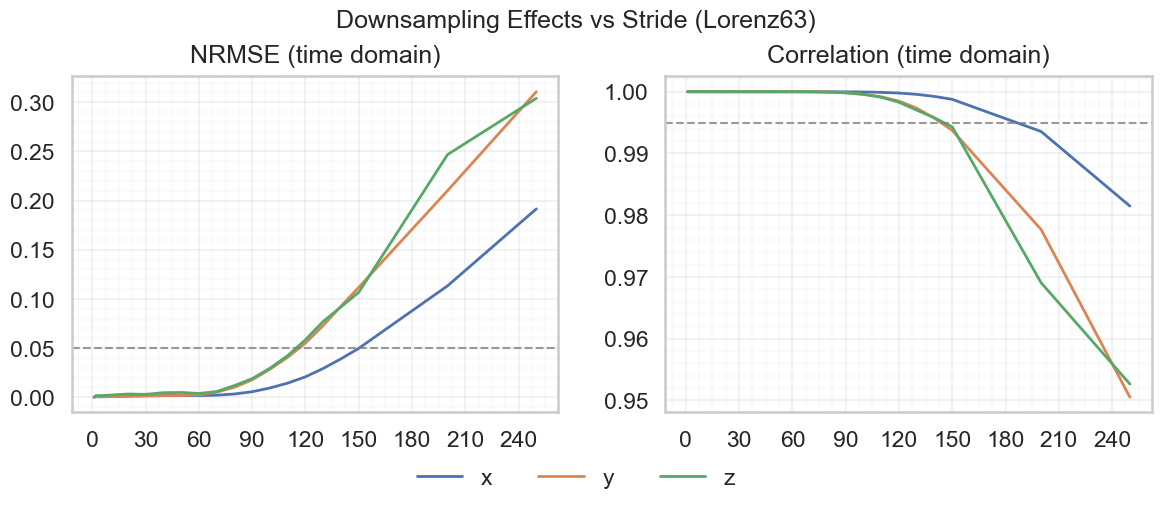

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

sns.set_theme(style="whitegrid", context="talk")

# Only these two metrics
metrics = ["nrmse_time", "corr_time"]
titles  = ["NRMSE (time domain)", "Correlation (time domain)"]

ideal_lines = {
    "nrmse_time": 0.05,   # below this = excellent
    "corr_time": 0.995,   # above this = excellent
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True)
fig.subplots_adjust(left=0.08, right=0.98, top=0.88, bottom=0.18, wspace=0.22)

for ax, metric, title in zip(axes, metrics, titles):
    sns.lineplot(
        data=df_metrics,
        x="stride", y=metric,
        hue="axis", linewidth=2, ax=ax
    )
    ax.set_title(title, pad=10)
    ax.set_xlabel("")  # keep empty like before
    ax.set_ylabel("")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(True, which="major", alpha=0.25)
    ax.minorticks_on()
    ax.grid(True, which="minor", alpha=0.08)

    # Optional: dashed vertical reference for stride=50
    # ax.axvline(50, ls="--", lw=1.5, color="navy")

    # Horizontal "ideal" line
    ax.axhline(ideal_lines[metric], ls="--", lw=1.5, color="gray", alpha=0.8)

# remove subplot legends
for ax in axes:
    leg = ax.get_legend()
    if leg:
        leg.remove()

# unified legend at bottom
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, -0.02))

plt.suptitle("Downsampling Effects vs Stride (Lorenz63)", y=1.02, fontsize=18)
plt.show()
fig.savefig("downsample_stats.pdf", bbox_inches="tight")
fig.savefig("downsample_stats.png", dpi=300, bbox_inches="tight")


## 5. Interpreting the metrics (why 50 is a good choice)

- **NRMSE (time)** stays **low** and **correlation** remains **high** at `stride=50`, indicating that the downsampled series (and its simple upsample back to 1 kHz for comparison) aligns closely with the original in the time domain.
- **PSD energy below `f_cut`** is ≈ **1.0** before and after downsampling, meaning we preserve essentially all energy in the band we consider important for ESN state evolution.
- **JSD between PSDs** remains **small**, so the spectral character is nearly unchanged by downsampling to `20 Hz`.

This gives us strong evidence that a `50×` reduction (to 20 Hz) is a **sweet spot**: fast training and good generalization, without discarding dynamics essential to predicting Lorenz‑63.


## 6. Notes on `t = 1,000,000`

Interpreting `t` as **seconds** with `dt=0.001` would imply ~**1e9 samples**, which is massive for in‑memory work. For end‑to‑end ESN training, structure the pipeline to **stream** or **chunk** the long trajectory to disk (e.g., segmented `.npy`/Parquet shards) and repeat the same metric checks per chunk. The analysis above is designed to be identical for chunks and the full run.

> If your `t` denotes **number of steps** instead of seconds, adjust the notebook’s `n_steps` accordingly—the logic here remains the same.


In [6]:
import numpy as np
from src.series_statistics import *

# ---- KL helpers (reuse from earlier message if not already imported) ----
from scipy.stats import entropy

def make_pmf(x, bins, eps=1e-12):
    counts, _ = np.histogram(x, bins=bins, density=False)
    p = counts.astype(float) + eps
    p /= p.sum()
    return p

def ref_bins(x_ref, bins="fd"):
    return np.histogram_bin_edges(x_ref, bins=bins)

def kl_time_series(x, dt, bins, win_s=5.0, step_s=1.0, base=2, eps=1e-12, ref_p=None):
    if ref_p is None:
        raise ValueError("Provide ref_p (PMF built on shared bins).")
    win_n  = max(1, int(round(win_s / dt)))
    step_n = max(1, int(round(step_s / dt)))
    t0s, kls = [], []
    for start in range(0, len(x) - win_n + 1, step_n):
        seg = x[start:start + win_n]
        p = make_pmf(seg, bins, eps=eps)
        kls.append(entropy(p, qk=ref_p, base=base))
        t0s.append(start * dt)
    return np.asarray(t0s), np.asarray(kls)

# ---- Optimal stride finder ------------------------------------------------
def find_optimal_stride(
    x, y, z, dt,
    strides=(2,4,6,8,10,12,16,20,24),
    f_cut=None,
    kl_win_s=5.0, kl_step_s=1.0,
    thresholds=None,
):
    """
    Returns:
      chosen_stride, per_stride_summary(list of dict), df_metrics(from analyze_resampling_axes)
    Requires your analyze_resampling_axes() to be available.
    """
    # Default thresholds (tune!)
    if thresholds is None:
        thresholds = {
            "nrmse_max": 0.05,
            "corr_min": 0.995,
            "psd_js_max": 0.05,
            "peak_rel_max": 0.03,
            "kl_median_max": 0.02,   # bits
            "kl_p90_max": 0.05,      # bits
        }

    fs = 1.0 / dt
    # 1) Base metrics for each axis/stride (NRMSE, corr, JSD...)
    df_metrics, artifacts = analyze_resampling_axes(
        x, y, z, fs, strides=strides, f_cut=f_cut, make_plots=False
    )

    # 2) KL reference (shared bins & PMF from pooled original)
    pooled = np.concatenate([x, y, z])
    bins_common = ref_bins(pooled, bins="fd")
    ref_p_common = make_pmf(pooled, bins_common, eps=1e-12)

    # 3) Compute KL stats per axis/stride on the upsampled signals (aligned to original dt)
    kl_stats = []  # rows: {axis, stride, kl_median, kl_p90, kl_slope}
    for axis_name, sig in [("x", x), ("y", y), ("z", z)]:
        for s in strides:
            x_up = artifacts[axis_name][s]["x_up"]  # after down->up
            t, kl_vals = kl_time_series(
                x_up, dt, bins_common, win_s=kl_win_s, step_s=kl_step_s,
                base=2, ref_p=ref_p_common
            )
            if len(kl_vals) >= 3:
                # slope on last third (stability)
                m0 = len(kl_vals) // 3 * 2
                coef = np.polyfit(t[m0:], kl_vals[m0:], 1)
                slope = float(coef[0])
            else:
                slope = 0.0
            kl_stats.append({
                "axis": axis_name, "stride": s,
                "kl_median": float(np.median(kl_vals)),
                "kl_p90": float(np.quantile(kl_vals, 0.90)),
                "kl_slope": slope,
            })

    # 4) Aggregate per stride (take worst across axes to be conservative)
    per_stride = []
    for s in strides:
        row_s = df_metrics[df_metrics["stride"] == s]
        # worst (max) NRMSE, worst (min) corr, worst (max) PSD-JSD across axes
        nrmse_worst = float(row_s["nrmse_time"].max())
        corr_worst  = float(row_s["corr_time"].min())
        jsd_worst   = float(row_s["jsd_psd"].max())

        # KL worst across axes for this stride
        ks = [r for r in kl_stats if r["stride"] == s]
        kl_median_worst = float(max(r["kl_median"] for r in ks))
        kl_p90_worst    = float(max(r["kl_p90"] for r in ks))
        # (optional) slope_worst = max(abs(r["kl_slope"]) for r in ks)

        # pass/fail gates
        passed = (
            (nrmse_worst <= thresholds["nrmse_max"]) and
            (corr_worst  >= thresholds["corr_min"])   and
            (jsd_worst   <= thresholds["psd_js_max"]) and
            (kl_median_worst <= thresholds["kl_median_max"]) and
            (kl_p90_worst    <= thresholds["kl_p90_max"])
        )

        per_stride.append({
            "stride": s,
            "nrmse_worst": nrmse_worst,
            "corr_worst": corr_worst,
            "psd_js_worst": jsd_worst,
            "kl_median_worst": kl_median_worst,
            "kl_p90_worst": kl_p90_worst,
            "pass": bool(passed),
        })

    # 5) Choose largest passing stride; fallback to composite score
    passing = [r for r in per_stride if r["pass"]]
    if passing:
        chosen = max(passing, key=lambda r: r["stride"])["stride"]
    else:
        # Normalize and rank by a simple composite score if nothing passes
        # smaller is better: (nrmse + jsd + kl_median + 0.5*kl_p90) - corr
        def score(r):
            return (r["nrmse_worst"] +
                    r["psd_js_worst"] +
                    r["kl_median_worst"] +
                    0.5*r["kl_p90_worst"] -
                    0.5*r["corr_worst"])
        chosen = min(per_stride, key=score)["stride"]

    return chosen, per_stride, df_metrics


In [ ]:
# Given arrays x,y,z and dt:
best_stride, summary, df_axes = find_optimal_stride(
    xs, ys, zs, dt,
    strides=strides,#(2,4,6,8,10,12,14,16,18,20,24),
    f_cut=(1/dt)/10,     # or None to auto inside analyze_resampling
    kl_win_s=5.0, kl_step_s=1.0
)

print("Chosen stride:", best_stride)
for row in summary:
    print(row)
